# Importação dos dados brutos

> Arquivo drug_consumption.csv

In [66]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "mexwell/drug-consumption-classification",
  "drug_consumption.csv",
)

print(df.shape)
df.head()

Using Colab cache for faster access to the 'drug-consumption-classification' dataset.
(1885, 32)


,ID,Age,Gender,Education,Country,Ethnicity,Nscore,Escore,Oscore,Ascore,...,Ecstasy,Heroin,Ketamine,Legalh,LSD,Meth,Mushrooms,Nicotine,Semer,VSA
0,1,0.49788,0.48246,-0.05921,0.96082,0.12600,0.31287,-0.57545,-0.58331,-0.91699,...,CL0,CL0,CL0,CL0,CL0,CL0,CL0,CL2,CL0,CL0
1,2,-0.07854,-0.48246,1.98437,0.96082,-0.31685,-0.67825,1.93886,1.43533,0.76096,...,CL4,CL0,CL2,CL0,CL2,CL3,CL0,CL4,CL0,CL0
2,3,0.49788,-0.48246,-0.05921,0.96082,-0.31685,-0.46725,0.80523,-0.84732,-1.62090,...,CL0,CL0,CL0,CL0,CL0,CL0,CL1,CL0,CL0,CL0
3,4,-0.95197,0.48246,1.16365,0.96082,-0.31685,-0.14882,-0.80615,-0.01928,0.59042,...,CL0,CL0,CL2,CL0,CL0,CL0,CL0,CL2,CL0,CL0
4,5,0.49788,0.48246,1.98437,0.96082,-0.31685,0.73545,-1.63340,-0.45174,-0.30172,...,CL1,CL0,CL0,CL1,CL0,CL0,CL2,CL2,CL0,CL0


In [67]:
df.columns = df.columns.str.lower()

COLUNAS_ORDINAIS = ["age", "education"]
COLUNAS_NOMINAIS = ["gender", "country", "ethnicity"]
COLUNAS_PERSONALIDADE = ["nscore", "escore", "oscore", "ascore", "cscore", "impuslive", "ss"]
COLUNAS_CONSUMO = df.select_dtypes(exclude="number").columns  # colunas de droga, com valores de CL0 a CL6

---
# Dados da Tabela 1

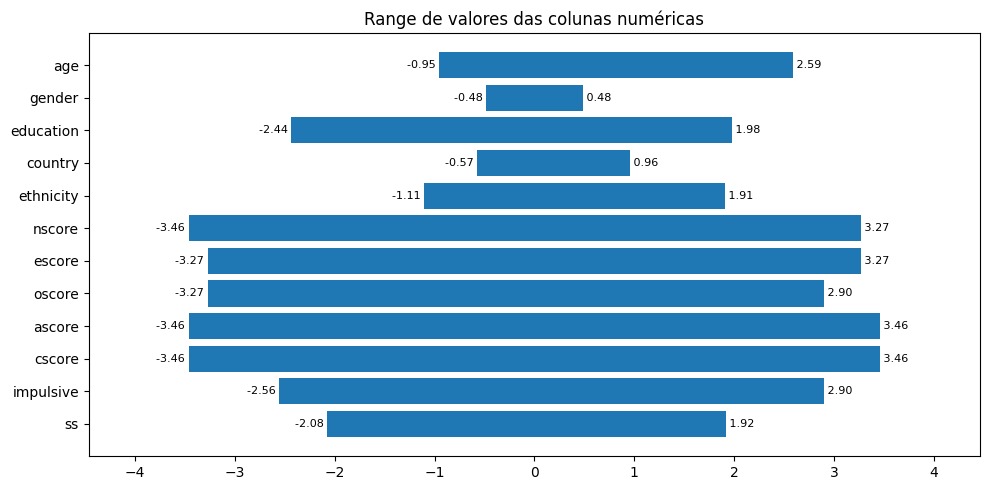

In [68]:
from matplotlib import pyplot as plt

colunas_numericas = df.select_dtypes("float").columns  # demografia + personalidade (o id é inteiro e fica de fora)
minimos = df[colunas_numericas].min()
maximos = df[colunas_numericas].max()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(colunas_numericas, maximos - minimos, left=minimos)  # cada barra começa no mínimo e termina no máximo
for posicao, coluna in enumerate(colunas_numericas):  # escreve o mínimo à esquerda e o máximo à direita da barra
    ax.text(minimos[coluna], posicao, f"{minimos[coluna]:.2f} ", ha="right", va="center", fontsize=8)
    ax.text(maximos[coluna], posicao, f" {maximos[coluna]:.2f}", ha="left", va="center", fontsize=8)
ax.set_xlim(minimos.min() - 1, maximos.max() + 1)  # folga para os rótulos não saírem do gráfico
ax.invert_yaxis()  # mostra as colunas na mesma ordem do dataset
ax.set_title("Range de valores das colunas numéricas")
plt.tight_layout()
plt.show()

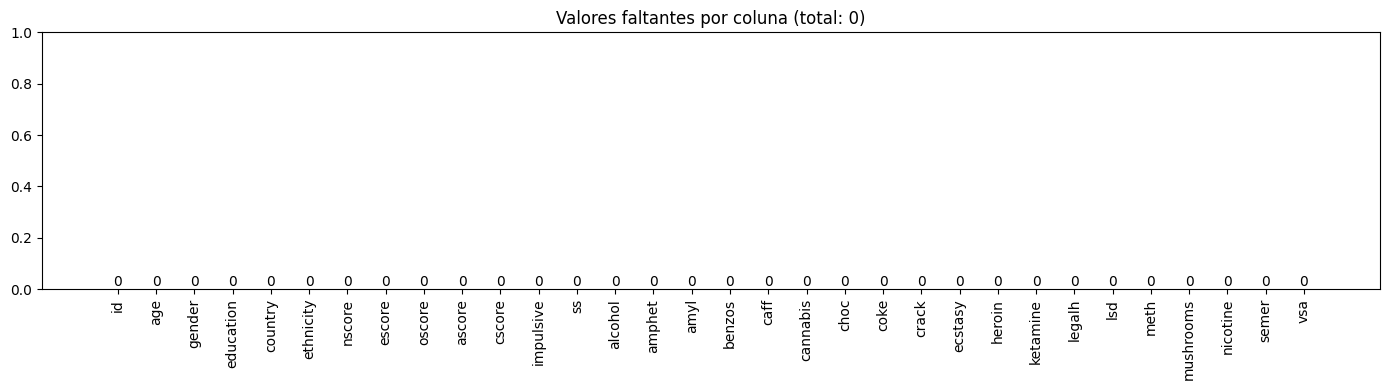

In [69]:
faltantes = df.isna().sum()  # quantidade de valores vazios em cada coluna

fig, ax = plt.subplots(figsize=(14, 4))
barras = ax.bar(faltantes.index, faltantes)
ax.bar_label(barras)
ax.set_ylim(0, faltantes.max() + 1)  # sem isso o eixo fica de 0 a 0 quando não há faltantes
ax.tick_params(axis="x", rotation=90)
ax.set_title(f"Valores faltantes por coluna (total: {faltantes.sum()})")
plt.tight_layout()
plt.show()

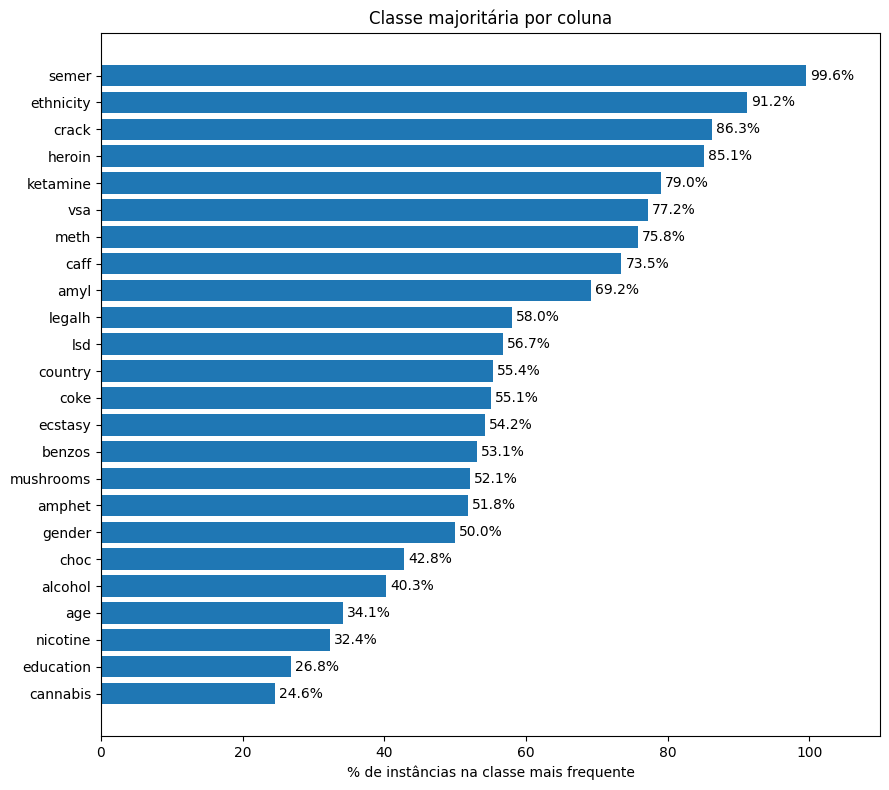

In [70]:
colunas_categoricas = COLUNAS_ORDINAIS + COLUNAS_NOMINAIS + list(COLUNAS_CONSUMO)  # personalidade e id não têm classes
classe_majoritaria = df[colunas_categoricas].apply(lambda coluna: coluna.value_counts(normalize=True).max() * 100)  # % de linhas na classe mais frequente
classe_majoritaria = classe_majoritaria.sort_values(ascending=False)  # mais desbalanceada no topo

fig, ax = plt.subplots(figsize=(9, 8))
barras = ax.barh(classe_majoritaria.index, classe_majoritaria)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.set_xlim(0, 110)  # folga para o rótulo das barras perto de 100%
ax.invert_yaxis()
ax.set_xlabel("% de instâncias na classe mais frequente")
ax.set_title("Classe majoritária por coluna")
plt.tight_layout()
plt.show()

# Pré-processamento

## Normalização
> Remoção de dados de pessoas que relataram consumo de "semeron".
>
> Droga fictícia criada pelo autor do dataset para filtrar o que ele chama de "over-claimers", ou pessoas que fizeram a pesquisa sem informar dados verídicos.

> Nomes de colunas em caixa-baixa
>
> Redução do número de colunas 32 -> 14

In [74]:
print(df.loc[df["semer"] != "CL0"].shape[0])
df.drop(columns=df.columns[(df != 'CL0').any()])

COLUNAS_INUTILIZADAS = ["alcohol", "amphet", "amyl", "benzos", "caff", "choc",
    "coke", "crack", "ecstasy", "heroin", "ketamine", "legalh",
    "lsd", "meth", "mushrooms", "nicotine", "semer", "vsa"]

df.drop(COLUNAS_INUTILIZADAS, axis=1, inplace=True, errors='ignore')
print(df.shape)

8
(1885, 14)


## Caracterização dos dados

---

O dataset informa o que significa cada campo no link: https://www.kaggle.com/datasets/mexwell/drug-consumption-classification



In [75]:
CLASSES_CONSUMO = {
    "CL0": "Nunca usou",
    "CL1": "Há mais de 10 anos",
    "CL2": "Nos últimos 10 anos",
    "CL3": "No último ano",
    "CL4": "No último mês",
    "CL5": "Na última semana",
    "CL6": "No último dia",
}

## Treinamento dos modelos

Selecionados os modelos do sklearn:
- LogisticRegression
- RandomForestClassifier
- SVC (Support Vector Classifier)

Os dados totais do dataset são separados em dados de treinamento e dados para testes, com uma relação 80/20
- 80% dos dados para treinamento
- 20% para testar os modelos em seguida


### Avaliando os modelos

Nesse primeiro passo, avaliamos a acurácia, precisão, recall e f1-score dos modelos na classificação entre as 7 categorias possíveis, de CLO a CL6

,Model,Training Time (s),Accuracy,Precision,Recall,F1-Score
0,Logistic Regression (Multiclass),0.141300,0.424403,0.423564,0.424403,0.350163
1,Random Forest (Multiclass),1.658609,0.384615,0.314303,0.384615,0.319975
2,Support Vector Classifier (Multiclass),0.422366,0.427056,0.319070,0.427056,0.329815


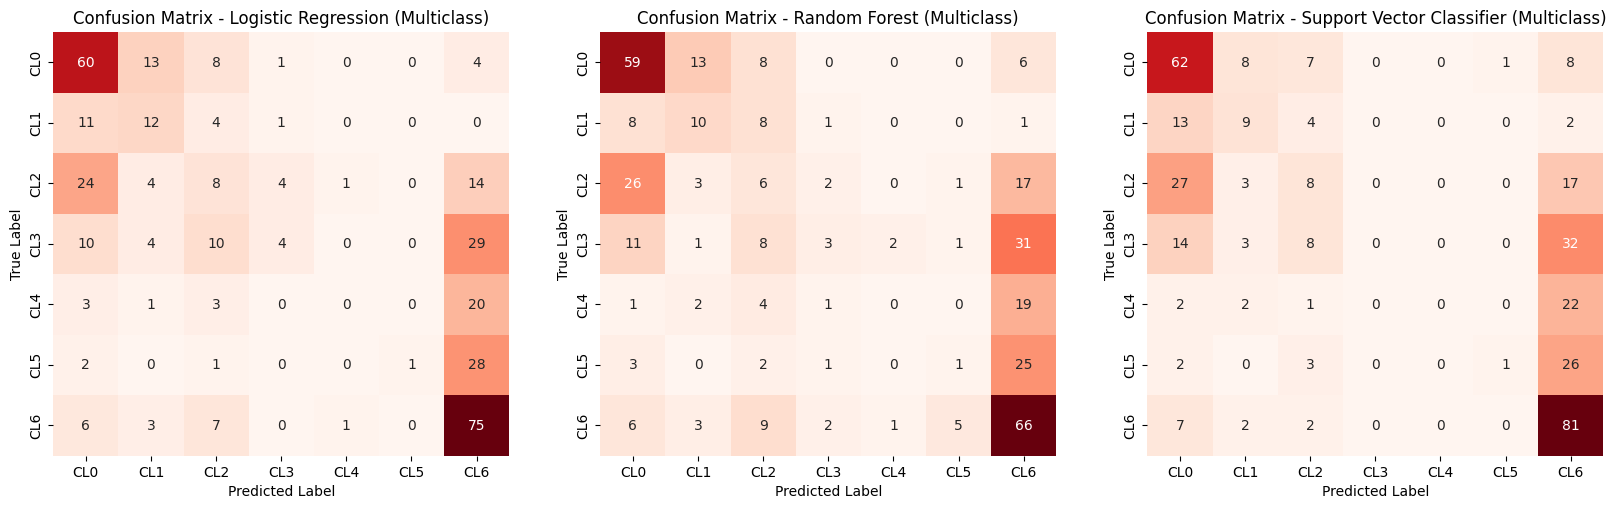

In [84]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Defining target and features
# After dropping 18 drug columns, the target variable remaining is 'cannabis'
target_col = 'cannabis'
feature_cols = [col for col in df.columns if col != target_col and col != 'id']

# Prepare X and y
X = df[feature_cols]
y = df[target_col]

# One-hot encode categorical features if they are not already numeric
X = pd.get_dummies(X, columns=['gender', 'country', 'ethnicity'], drop_first=True)

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Definindo novamente os classificadores para a tarefa multi-classe
multiclass_models = {
    "Logistic Regression (Multiclass)": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest (Multiclass)": RandomForestClassifier(random_state=42),
    "Support Vector Classifier (Multiclass)": SVC(random_state=42)
}

multiclass_results = []

classes_ordenadas = sorted(list(df[target_col].unique()))
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, (name, model) in zip(axes, multiclass_models.items()):
    # Treinar e medir o tempo
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time

    # Predição
    y_pred_multi = model.predict(X_test_scaled)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_test, y_pred_multi, labels=classes_ordenadas)

    # Plotar o heatmap no respectivo eixo
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=ax,
                xticklabels=classes_ordenadas, yticklabels=classes_ordenadas,
                cbar=False)

    ax.set_title(f'Confusion Matrix - {name}', fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

    # Cálculo das métricas
    accuracy = accuracy_score(y_test, y_pred_multi)
    precision = precision_score(y_test, y_pred_multi, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred_multi, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred_multi, average='weighted', zero_division=0)

    multiclass_results.append({
        "Model": name,
        "Training Time (s)": train_time,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

multiclass_metrics_df = pd.DataFrame(multiclass_results)
display(multiclass_metrics_df)

plt.show()

Nos modelos treinados acima, notamos que a assertividade dos modelos foi baixa. Isso porque pode ser desafiador para o modelo classificar entre as 7 classes disponíveis, e todos eles tenderam a apostar mais nos extremos, gerando um mapa de calor similar.

### Classificação binária

Para contornar esse problema, uma solução possível é separar os dados em 2 categorias apenas.

- CL0 e CL1: Pessoa nunca usou ou usou há muito tempo.
- CL2 a CL6: Pessoa que utiliza ou já utilizou em um período recente.


,Model,Training Time (s),Accuracy,Precision,Recall,F1-Score
0,Logistic Regression (Binary),0.013378,0.822281,0.888889,0.851711,0.869903
1,Random Forest (Binary),0.514255,0.806366,0.868217,0.851711,0.859885
2,Support Vector Classifier (Binary),0.098924,0.822281,0.876923,0.866920,0.871893


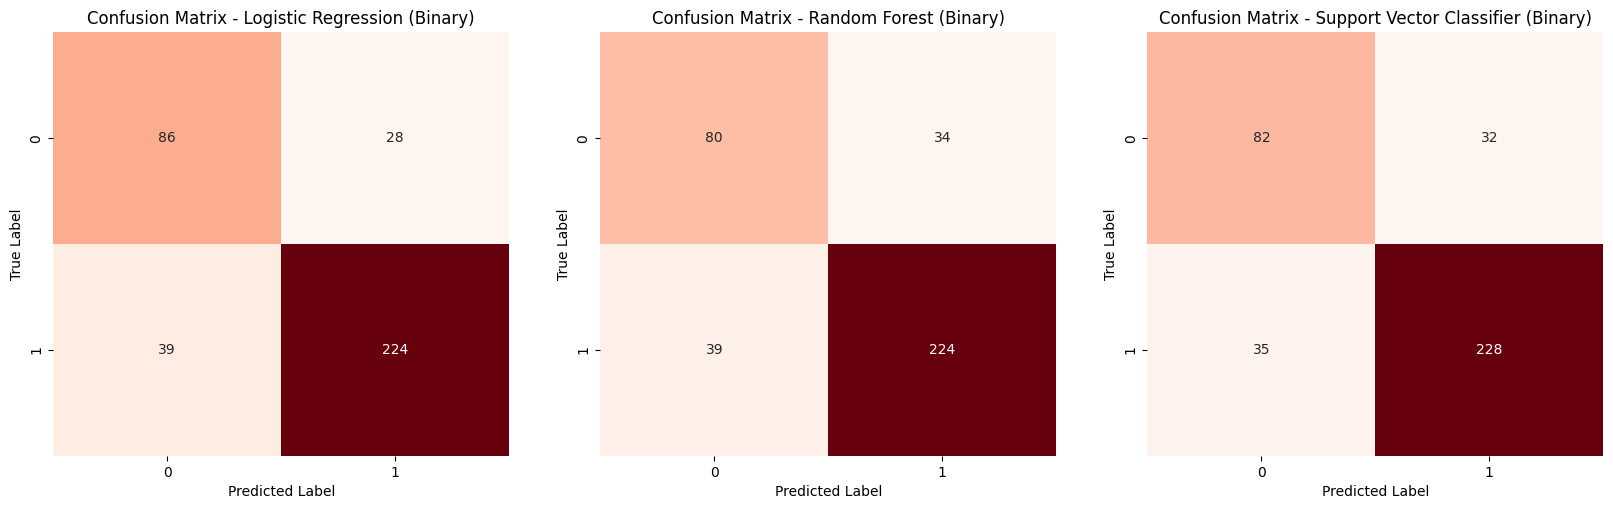

In [94]:
binary_map = {'CL0': 0, 'CL1': 0, 'CL2': 1, 'CL3': 1, 'CL4': 1, 'CL5': 1, 'CL6': 1}
y_binary = df[target_col].map(binary_map)

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)

# Normalização dos dados
scaler = StandardScaler()
X_train_bin_scaled = scaler.fit_transform(X_train_bin)
X_test_bin_scaled = scaler.transform(X_test_bin)

# Definição dos modelos para a tarefa binária
binary_models = {
    "Logistic Regression (Binary)": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest (Binary)": RandomForestClassifier(random_state=42),
    "Support Vector Classifier (Binary)": SVC(random_state=42)
}

binary_results = []

classes_ordenadas = [0, 1]
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, (name, model) in zip(axes, binary_models.items()):
    # Treinar e medir o tempo
    start_time = time.time()
    model.fit(X_train_bin_scaled, y_train_bin)
    train_time = time.time() - start_time

    # Predição
    y_pred_bin = model.predict(X_test_bin_scaled)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_test_bin, y_pred_bin, labels=classes_ordenadas)

    # Plotar o heatmap no respectivo eixo
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=ax,
                xticklabels=classes_ordenadas, yticklabels=classes_ordenadas,
                cbar=False)

    ax.set_title(f'Confusion Matrix - {name}', fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

    # Cálculo das métricas
    accuracy = accuracy_score(y_test_bin, y_pred_bin)
    precision = precision_score(y_test_bin, y_pred_bin, zero_division=0)
    recall = recall_score(y_test_bin, y_pred_bin, zero_division=0)
    f1 = f1_score(y_test_bin, y_pred_bin, zero_division=0)

    binary_results.append({
        "Model": name,
        "Training Time (s)": train_time,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

binary_metrics_df = pd.DataFrame(binary_results)
display(binary_metrics_df)

plt.show()

In [ ]:
# Criar a figura com 3 subplots lado a lado
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for ax, (name, model) in zip(axes, multiclass_models.items()):
    # Obter predições do respectivo modelo
    y_pred = model.predict(X_test_scaled)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_test, y_pred, labels=classes_ordenadas)

    # Plotar o heatmap no respectivo eixo
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=ax,
                xticklabels=classes_ordenadas, yticklabels=classes_ordenadas,
                cbar=False)

    ax.set_title(f'Confusion Matrix - {name}', fontsize=12)
    ax.set_xlabel('Predicted Label', fontsize=10)
    ax.set_ylabel('True Label', fontsize=10)

plt.show()

Na tabela acima, é perceptível o quanto a acurácia dos modelos subiu de maneira geral.

Isso ocorre, principalmente porque há menor margem para erro. 2 opções ao invés de 7, mas também por conta do agrupamento.

In [98]:
# Contagem de dados para cada classe de consumo de Cannabis
cannabis_counts = df['cannabis'].value_counts().reset_index()
cannabis_counts.columns = ['Classe (Código)', 'Quantidade de Registros']

# Reordenando as colunas para melhor visualização
cannabis_counts = cannabis_counts[['Classe (Código)', 'Quantidade de Registros']].sort_values('Classe (Código)')

display(cannabis_counts)

,Classe (Código),Quantidade de Registros
1,CL0,413
4,CL1,207
2,CL2,266
3,CL3,211
6,CL4,140
5,CL5,185
0,CL6,463
